# Solutions to notebook 6: Differential equations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/06_differential_equations.ipynb)

Worked solutions to the exercises at the end of [notebook 6](../notebooks/06_differential_equations.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = sp.symbols("t", nonnegative=True)

## Exercise 1

A tank of volume $V$ holds brine of concentration $c_0$. Fresh water enters at flow rate $q$
and the mixture leaves at the same rate. Solve $V\,\dot c = -q c$ and find the time for the
concentration to fall to 1 % of its initial value.

In [2]:
V, q, c_0 = sp.symbols("V q c_0", positive=True)
c = sp.Function("c")

tank = sp.Eq(V * c(t).diff(t), -q * c(t))
c_sol = sp.dsolve(tank, c(t), ics={c(0): c_0})
c_sol

           -q⋅t 
           ─────
             V  
c(t) = c₀⋅ℯ     

In [3]:
# time at which c = c_0 / 100
t_1pct = sp.expand_log(sp.solve(sp.Eq(c_sol.rhs, c_0 / 100), t)[0], force=True)
t_1pct, float(sp.log(100))

⎛2⋅V⋅log(10)                   ⎞
⎜───────────, 4.605170185988092⎟
⎝     q                        ⎠

In [4]:
# verify: the solution satisfies the equation and the initial condition,
# and substituting the time back gives exactly 1 % of c_0
assert sp.checkodesol(tank, c_sol)[0] and c_sol.rhs.subs(t, 0) == c_0
assert sp.simplify(c_sol.rhs.subs(t, V * sp.log(100) / q) / c_0) == sp.Rational(1, 100)
assert sp.simplify(t_1pct - V * sp.log(100) / q) == 0

**Answer.** $c(t) = c_0\,e^{-qt/V}$, and the concentration reaches 1 % of $c_0$ at
$t = \dfrac{V}{q}\ln 100 \approx 4.61\,\dfrac{V}{q}$. The tank must be flushed with about 4.6 times
its own volume of water.

## Exercise 2

Solve the forced oscillator $\ddot x + 2\zeta\dot x + x = \cos(\Omega t)$ for $\zeta = 1/10$
and plot the steady-state amplitude against $\Omega$. Where is the resonance peak?

In [5]:
Omega = sp.symbols("Omega", positive=True)
zeta = sp.Rational(1, 10)
x = sp.Function("x")

forced = sp.Eq(x(t).diff(t, 2) + 2 * zeta * x(t).diff(t) + x(t), sp.cos(Omega * t))
general = sp.dsolve(forced, x(t))
general

                                                                               ↪
               2                                                               ↪
           25⋅Ω ⋅cos(Ω⋅t)        5⋅Ω⋅sin(Ω⋅t)      ⎛      ⎛3⋅√11⋅t⎞         ⎛3 ↪
x(t) = - ────────────────── + ────────────────── + ⎜C₁⋅sin⎜───────⎟ + C₂⋅cos⎜─ ↪
             4       2            4       2        ⎝      ⎝  10   ⎠         ⎝  ↪
         25⋅Ω  - 49⋅Ω  + 25   25⋅Ω  - 49⋅Ω  + 25                               ↪

↪           -t                      
↪           ───                     
↪ ⋅√11⋅t⎞⎞  10       25⋅cos(Ω⋅t)    
↪ ──────⎟⎟⋅ℯ    + ──────────────────
↪  10   ⎠⎠            4       2     
↪                 25⋅Ω  - 49⋅Ω  + 25

The terms with $C_1$ and $C_2$ are multiplied by $e^{-t/10}$ and die away whatever the initial
conditions. What remains is the steady state, $a\cos\Omega t + b\sin\Omega t$, whose amplitude is
$\sqrt{a^2 + b^2}$.

In [6]:
C1, C2 = sp.symbols("C1 C2")
steady = general.rhs.subs({C1: 0, C2: 0})

a_cos = steady.coeff(sp.cos(Omega * t))
b_sin = steady.coeff(sp.sin(Omega * t))
amplitude_sq = sp.simplify(a_cos**2 + b_sin**2)
amplitude = sp.sqrt(amplitude_sq)
amplitude

       ____________________
      ╱         1          
5⋅   ╱  ────────────────── 
    ╱       4       2      
  ╲╱    25⋅Ω  - 49⋅Ω  + 25 

In [7]:
# the peak: differentiate the squared amplitude (same maximum, no square root to get in the way)
Omega_peak = sp.solve(sp.diff(amplitude_sq, Omega), Omega)[0]
peak = sp.simplify(amplitude.subs(Omega, Omega_peak))
Omega_peak, peak, float(Omega_peak), float(peak)

⎛7⋅√2  50⋅√11                                      ⎞
⎜────, ──────, 0.9899494936611666, 5.02518907629606⎟
⎝ 10     33                                        ⎠

In [8]:
# verify: the steady state satisfies the equation, and the amplitude and the peak agree with the
# textbook formulas 1/sqrt((1 - Ω²)² + (2ζΩ)²), Ω_peak = sqrt(1 - 2ζ²), peak = 1/(2ζ sqrt(1 - ζ²))
assert sp.checkodesol(forced, sp.Eq(x(t), steady))[0]
assert sp.simplify(amplitude_sq - 1 / ((1 - Omega**2) ** 2 + (2 * zeta * Omega) ** 2)) == 0
assert sp.simplify(Omega_peak - sp.sqrt(1 - 2 * zeta**2)) == 0
assert sp.simplify(peak - 1 / (2 * zeta * sp.sqrt(1 - zeta**2))) == 0
assert amplitude.subs(Omega, 0) == 1          # a very slow force gives the static deflection

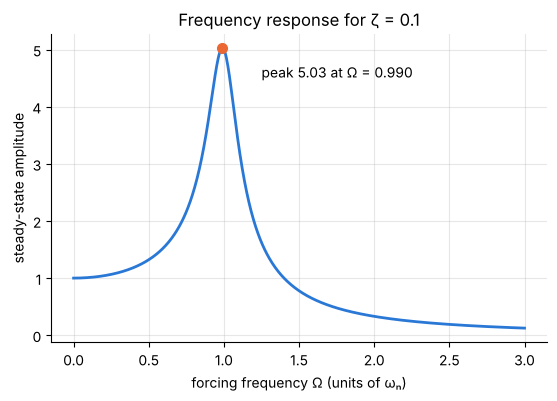

In [9]:
Omegas = np.linspace(0, 3, 600)
fig, ax = plt.subplots()
ax.plot(Omegas, sp.lambdify(Omega, amplitude, "numpy")(Omegas))
ax.plot(float(Omega_peak), float(peak), "o", color="#eb6834", ms=7)
ax.annotate(f"peak {float(peak):.2f} at Ω = {float(Omega_peak):.3f}", xy=(float(Omega_peak), float(peak)),
            xytext=(1.25, 4.6), va="center")
ax.set(xlabel="forcing frequency Ω (units of ωₙ)", ylabel="steady-state amplitude",
       title="Frequency response for ζ = 0.1");

**Answer.** The steady-state amplitude is $\dfrac{5}{\sqrt{25\Omega^4 - 49\Omega^2 + 25}}
= \dfrac{1}{\sqrt{(1-\Omega^2)^2 + (2\zeta\Omega)^2}}$. It peaks at
$\Omega = \sqrt{1 - 2\zeta^2} = 7\sqrt2/10 \approx 0.990$, just below the natural frequency, where
the amplitude is $50\sqrt{11}/33 \approx 5.03$ times the static deflection.

## Exercise 3

Repeat 6.3 for flow between two parallel plates a distance $2h$ apart. The mean velocity
should be two thirds of the maximum.

With $y$ measured from the mid-plane, the momentum balance is $\mu\,\dfrac{d^2u}{dy^2} = -G$ with
no slip at both walls, $u(\pm h) = 0$. There is no singular point this time, so `dsolve` accepts
both conditions directly.

In [10]:
y = sp.symbols("y", real=True)                 # runs from -h to h, so not declared positive
h, mu, G = sp.symbols("h mu G", positive=True)
u = sp.Function("u")

momentum = sp.Eq(mu * u(y).diff(y, 2), -G)
u_plates = sp.factor(sp.dsolve(momentum, u(y), ics={u(-h): 0, u(h): 0}).rhs)
u_plates

-G⋅(-h + y)⋅(h + y) 
────────────────────
        2⋅μ         

In [11]:
flow = sp.integrate(u_plates, (y, -h, h))      # flow rate per unit width of plate
u_mean = sp.simplify(flow / (2 * h))
u_max = u_plates.subs(y, 0)
flow, u_mean, u_max, u_mean / u_max

⎛     3     2     2     ⎞
⎜2⋅G⋅h   G⋅h   G⋅h      ⎟
⎜──────, ────, ────, 2/3⎟
⎝ 3⋅μ    3⋅μ   2⋅μ      ⎠

In [12]:
# verify: equation, both walls, symmetry about the mid-plane, and the ratio stated in the exercise
assert sp.checkodesol(momentum, sp.Eq(u(y), u_plates))[0]
assert u_plates.subs(y, h) == 0 and u_plates.subs(y, -h) == 0
assert u_plates.diff(y).subs(y, 0) == 0
assert sp.simplify(u_mean / u_max) == sp.Rational(2, 3)
assert sp.simplify(flow - 2 * G * h**3 / (3 * mu)) == 0

**Answer.** $u(y) = \dfrac{G}{2\mu}\,(h^2 - y^2)$, with maximum $Gh^2/(2\mu)$ on the mid-plane and
mean $Gh^2/(3\mu)$, so the mean is two thirds of the maximum. The flow rate per unit width is
$2Gh^3/(3\mu)$. In the pipe the mean was half the maximum: the parabola is the same, but a pipe
has more of its area near the wall.

## Exercise 4

Change the fin tip condition to a fixed temperature $\theta(L) = 0$ and compare the heat flow.

In [13]:
xs, L, m, theta_b = sp.symbols("x L m theta_b", positive=True)
theta = sp.Function("theta")

fin = theta(xs).diff(xs, 2) - m**2 * theta(xs)
fixed_tip = sp.dsolve(fin, theta(xs), ics={theta(0): theta_b, theta(L): 0}).rhs
sp.simplify(fixed_tip)

    ⎛ 2⋅L⋅m    2⋅m⋅x⎞  -m⋅x
θ_b⋅⎝ℯ      - ℯ     ⎠⋅ℯ    
───────────────────────────
         2⋅L⋅m             
        ℯ      - 1         

In [14]:
# verify: the textbook form is a sinh profile
textbook = theta_b * sp.sinh(m * (L - xs)) / sp.sinh(m * L)
assert sp.simplify((fixed_tip - textbook).rewrite(sp.exp)) == 0
assert sp.simplify(textbook.diff(xs, 2) - m**2 * textbook) == 0
assert textbook.subs(xs, 0) == theta_b and textbook.subs(xs, L) == 0

The heat entering the fin at its base is proportional to $-\theta'(0)$. Compare it with the
insulated-tip fin of 6.4, $\theta = \theta_b\cosh m(L-x)/\cosh mL$.

In [15]:
insulated = theta_b * sp.cosh(m * (L - xs)) / sp.cosh(m * L)

slope_fixed = sp.simplify(-textbook.diff(xs).subs(xs, 0))
slope_insulated = sp.simplify(-insulated.diff(xs).subs(xs, 0))
ratio = sp.simplify(slope_fixed / slope_insulated)
slope_fixed, slope_insulated, ratio

⎛  m⋅θ_b                         1     ⎞
⎜─────────, m⋅θ_b⋅tanh(L⋅m), ──────────⎟
⎜tanh(L⋅m)                       2     ⎟
⎝                            tanh (L⋅m)⎠

In [16]:
# verify: hand results, and the two limiting cases
assert sp.simplify((slope_fixed - m * theta_b / sp.tanh(m * L)).rewrite(sp.exp)) == 0
assert sp.simplify((ratio - 1 / sp.tanh(m * L) ** 2).rewrite(sp.exp)) == 0
assert sp.limit(ratio, L, sp.oo) == 1                              # long fin: the tip does not matter
assert sp.limit(slope_fixed, m, 0) == theta_b / L                  # no surface loss: pure conduction to the tip

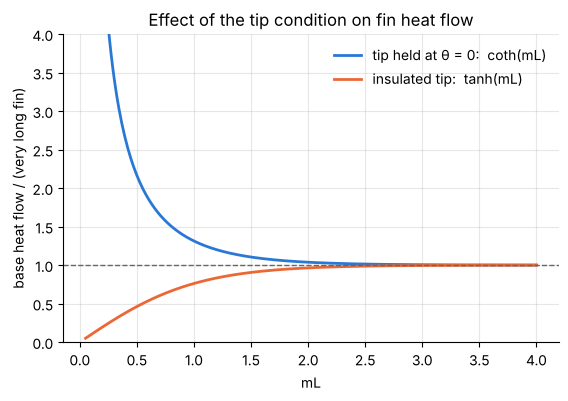

In [17]:
mL = np.linspace(0.05, 4, 300)
fig, ax = plt.subplots()
ax.plot(mL, 1 / np.tanh(mL), label="tip held at θ = 0:  coth(mL)")
ax.plot(mL, np.tanh(mL), label="insulated tip:  tanh(mL)")
ax.axhline(1, color="0.4", lw=1, ls="--")
ax.set(xlabel="mL", ylabel="base heat flow / (very long fin)", ylim=(0, 4),
       title="Effect of the tip condition on fin heat flow")
ax.legend(frameon=False);

**Answer.** $\theta = \theta_b\,\dfrac{\sinh m(L-x)}{\sinh mL}$, and the base heat flow is
proportional to $-\theta'(0) = m\theta_b\coth mL$, against $m\theta_b\tanh mL$ for the insulated
tip. The fixed-tip fin always carries more heat, by the factor $\coth^2 mL$, because heat now also
leaves by conduction through the tip. For a long fin ($mL \gtrsim 3$) the two agree and the tip
condition is irrelevant. For a short fin the fixed-tip heat flow tends to $\theta_b/L$, plain
conduction along a rod, while the insulated fin's heat flow tends to zero.

## Exercise 5

In 6.5, find the maximum concentration of $B$ as a function of $k_2/k_1$ only.

In [18]:
A, B, C = (sp.Function(name) for name in "ABC")
k1, k2, A0 = sp.symbols("k_1 k_2 A_0", positive=True)

kinetics = [
    sp.Eq(A(t).diff(t), -k1 * A(t)),
    sp.Eq(B(t).diff(t), k1 * A(t) - k2 * B(t)),
    sp.Eq(C(t).diff(t), k2 * B(t)),
]
series = sp.dsolve(kinetics, [A(t), B(t), C(t)], ics={A(0): A0, B(0): 0, C(0): 0})
A_t, B_t, C_t = (eq.rhs for eq in series)
t_max = sp.solve(sp.diff(B_t, t), t)[0]
t_max

    ⎛k₂⎞ 
-log⎜──⎟ 
    ⎝k₁⎠ 
─────────
 k₁ - k₂ 

In [19]:
# substitute the peak time, then write k_2 = kappa k_1: the rate constant k_1 cancels
kappa = sp.symbols("kappa", positive=True)
B_max = sp.simplify((B_t.subs(t, t_max) / A0).subs(k2, kappa * k1))
assert not B_max.has(k1)
B_max

   -κ⋅log(κ)     -log(κ) 
   ──────────    ────────
     κ - 1        κ - 1  
  ℯ             ℯ        
- ─────────── + ─────────
     κ - 1        κ - 1  

That expression is correct but not tidy. A hand argument gives a shorter form. At the peak
$\dot B = 0$, so $k_2 B = k_1 A$ and $B_{max} = A(t^*)/\kappa = A_0\,e^{-k_1 t^*}/\kappa$. With
$k_1 t^* = \ln(1/\kappa)/(1-\kappa)$ this is

$$\frac{B_{max}}{A_0} = \kappa^{\,\kappa/(1-\kappa)}, \qquad \kappa = \frac{k_2}{k_1}.$$

`simplify` does not find this form by itself, so verify that the two agree exactly at several
values of $\kappa$, and in the limit $\kappa \to 1$ where both become $1/e$.

In [20]:
compact = kappa ** (kappa / (1 - kappa))

for value in (sp.Rational(1, 10), sp.Rational(2, 5), sp.Rational(1, 2), 2, 3, 10):
    assert sp.simplify(B_max.subs(kappa, value) - compact.subs(kappa, value)) == 0
assert sp.limit(B_max, kappa, 1) == sp.limit(compact, kappa, 1) == sp.exp(-1)

# the lesson's numbers, k_1 = 1 and k_2 = 0.4: the peak of the B curve in the plot of 6.5
lesson = float(compact.subs(kappa, sp.Rational(2, 5)))
ts = np.linspace(0, 10, 100001)
curve_peak = sp.lambdify(t, B_t.subs({k1: 1.0, k2: 0.4, A0: 1.0}), "numpy")(ts).max()
assert abs(lesson - curve_peak) < 1e-8
print(f"k2/k1 = 0.4:  B_max / A_0 = {lesson:.4f}")

k2/k1 = 0.4:  B_max / A_0 = 0.5429


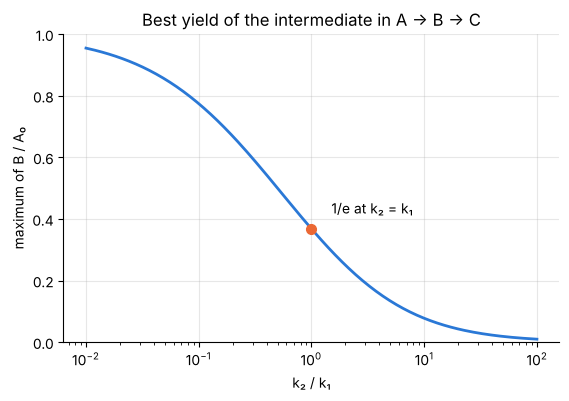

In [21]:
kappas = np.logspace(-2, 2, 200)               # an even number of points, so kappa = 1 is skipped
fig, ax = plt.subplots()
ax.semilogx(kappas, sp.lambdify(kappa, compact, "numpy")(kappas))
ax.plot(1, np.exp(-1), "o", color="#eb6834", ms=7)
ax.annotate("1/e at k₂ = k₁", xy=(1, np.exp(-1)), xytext=(1.5, np.exp(-1) + 0.05))
ax.set(xlabel="k₂ / k₁", ylabel="maximum of B / A₀", ylim=(0, 1),
       title="Best yield of the intermediate in A → B → C");

**Answer.** $\dfrac{B_{max}}{A_0} = \kappa^{\,\kappa/(1-\kappa)}$ with $\kappa = k_2/k_1$. It
depends only on the ratio of the rate constants, not on their size: faster reactions reach the
same peak sooner. For the lesson's values ($\kappa = 0.4$) the peak is $0.543\,A_0$. The yield
tends to 1 when $B$ is consumed slowly ($\kappa \to 0$), equals $1/e \approx 0.368$ when
$k_2 = k_1$, and tends to 0 when $B$ reacts away as fast as it forms ($\kappa \to \infty$).